# Chapter 41: Counting

Checks [chapter 41](../../book/41-counting.md). Three claims: a continuous read-out between two counts takes the half
(`exists_half_count`), the ideal denoiser blends two counts at an input equally far from both
(`denoiser_two_of_equidistant`), and a model that says `count` and `count + 1` at two inputs has slope at least one over
their distance (`one_le_slope_mul_dist_of_count`). A fourth experiment applies the third to an average over a sequence.
The models are small and exact: explicit read-outs on a path, the ideal denoiser of chapter 37 (softmax of minus squared
distance over two noise-level squared, a weighted mean of the examples), and smooth models built as a straight line plus
sine terms. None of them is trained. Everything is NumPy in float64, seeded. These are measurements, not proofs: the
proofs are in `Counting.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 41
GENERATOR = np.random.default_rng(SEED)


def find_crossing(readout, target, low=0.0, high=1.0, steps=200):
    """Bisect for a point where a continuous readout, below target at low and above it at high, equals target."""
    for _ in range(steps):
        middle = 0.5 * (low + high)
        if readout(middle) < target:
            low = middle
        else:
            high = middle
    return 0.5 * (low + high)


def denoise_ideally(noise_level, examples, noisy_input):
    """The ideal denoiser: softmax of minus squared distance over 2 noise_level^2, then the weighted mean."""
    squared_distances = ((examples - noisy_input) ** 2).sum(axis=1)
    scores = -squared_distances / (2.0 * noise_level ** 2)
    scores = scores - scores.max()
    shares = np.exp(scores) / np.exp(scores).sum()
    return shares @ examples


def measure_max_slope(model, low, high, points=200_001):
    inputs = np.linspace(low, high, points)
    return np.abs(np.diff(model(inputs)) / np.diff(inputs)).max()

## Claim 1: a continuous read-out between two counts says the half (`exists_half_count`)

Four read-outs on the path `[0, 1]`, all with `readout(0) = 5` and `readout(1) = 6`: `5 + fraction^2`, `5 + fraction`, a
steep smooth step `5 + 1 / (1 + exp(-40 (fraction - 0.3)))` rescaled so its ends are exactly 5 and 6, and
`5 + sin(pi fraction / 2)`. **Prediction:** each has a `fraction` in `[0, 1]` where it says 5.5, found by bisection to
within `1e-12`. For `5 + fraction^2` the place is `sqrt(0.5) = 0.7071`, the number in the chapter.

**Control:** break the hypothesis. A read-out with a jump, 5 for `fraction < 0.5` and 6 from there on, is not continuous.
**Prediction:** on a grid of 100 001 points it never comes within 0.4 of 5.5; its closest value to 5.5 is 0.5 away. If it
did say 5.5 somewhere, the control would not show what continuity buys.

In [2]:
def make_steep_step(steepness, centre):
    raw = lambda fraction: 1.0 / (1.0 + np.exp(-steepness * (fraction - centre)))
    low, high = raw(0.0), raw(1.0)
    return lambda fraction: 5.0 + (raw(fraction) - low) / (high - low)


READOUTS = {
    "5 + fraction^2": lambda fraction: 5.0 + fraction ** 2,
    "5 + fraction": lambda fraction: 5.0 + fraction,
    "steep smooth step": make_steep_step(40.0, 0.3),
    "5 + sin(pi fraction / 2)": lambda fraction: 5.0 + np.sin(0.5 * np.pi * fraction),
}

crossings = {}
for name, readout in READOUTS.items():
    assert abs(readout(0.0) - 5.0) < 1e-12
    assert abs(readout(1.0) - 6.0) < 1e-12
    fraction = find_crossing(readout, 5.5)
    crossings[name] = fraction
    print(f"{name:26s} says 5.5 at fraction {fraction:.4f} (value {readout(fraction):.12f})")

worst_miss = max(abs(READOUTS[name](fraction) - 5.5) for name, fraction in crossings.items())
report("a continuous read-out from 5 to 6 says 5.5 somewhere on the path",
       worst_miss < 1e-12 and abs(crossings["5 + fraction^2"] - np.sqrt(0.5)) < 1e-9,
       f"worst miss {worst_miss:.1e}; 5 + fraction^2 at {crossings['5 + fraction^2']:.4f}")

GRID = np.linspace(0.0, 1.0, 100_001)
jump_values = np.where(GRID < 0.5, 5.0, 6.0)
closest_to_half = np.abs(jump_values - 5.5).min()
report("control: a read-out with a jump never says 5.5", closest_to_half > 0.4,
       f"closest value to 5.5 is {closest_to_half:.3f} away")

5 + fraction^2             says 5.5 at fraction 0.7071 (value 5.500000000000)
5 + fraction               says 5.5 at fraction 0.5000 (value 5.500000000000)
steep smooth step          says 5.5 at fraction 0.3000 (value 5.500000000000)
5 + sin(pi fraction / 2)   says 5.5 at fraction 0.3333 (value 5.500000000000)
[PASS] a continuous read-out from 5 to 6 says 5.5 somewhere on the path  (worst miss 0.0e+00; 5 + fraction^2 at 0.7071)
[PASS] control: a read-out with a jump never says 5.5  (closest value to 5.5 is 0.500 away)


True

## Claim 2: the ideal denoiser blends two counts (`denoiser_two_of_equidistant`)

The chapter's hands: A is `(5, 0)` and B is `(6, 2)` (finger count, one other feature). The input `(7.5, 0)` is at distance
2.5 from both. **Prediction:** at noise levels 0.1, 0.5, 1, 3 and 10 the ideal denoiser returns `(5.5, 1)`, to within
`1e-9`, so the finger count is 5.5 at every noise level.

Then 200 random pairs of examples in 4 dimensions, with an input drawn on the perpendicular bisector (the midpoint plus a
random vector orthogonal to `B - A`, scaled to length 0 to 3). **Prediction:** the output is the midpoint, to within
`1e-9`, at a random noise level in [0.3, 5].

**Control:** move the input off the bisector, along the direction from A to B, by `offset` (so it is nearer to B). Shares
then differ: the share of B minus the share of A is `tanh(distance * offset / (2 * noise_level^2))`, where `distance` is
`|B - A|`. **Prediction:** the output leaves the midpoint by `(distance / 2) * tanh(...)` along that direction, and the
measured departure matches this formula to `1e-9`. For the chapter's hands at noise level 1 and offset 1,
`distance = sqrt(5)`, so about `1.118 * tanh(1.118) = 0.9`. The control fails the claim if that departure is below 0.1.

In [3]:
HAND_A, HAND_B = np.array([5.0, 0.0]), np.array([6.0, 2.0])
HANDS = np.stack([HAND_A, HAND_B])
NOISY_HAND_INPUT = np.array([7.5, 0.0])
NOISE_LEVELS = [0.1, 0.5, 1.0, 3.0, 10.0]

distance_to_a = np.linalg.norm(NOISY_HAND_INPUT - HAND_A)
distance_to_b = np.linalg.norm(NOISY_HAND_INPUT - HAND_B)
print(f"distance to A {distance_to_a:.4f}, distance to B {distance_to_b:.4f}")

hand_errors = []
for noise_level in NOISE_LEVELS:
    output = denoise_ideally(noise_level, HANDS, NOISY_HAND_INPUT)
    hand_errors.append(np.abs(output - np.array([5.5, 1.0])).max())
    print(f"noise level {noise_level:5.1f}: finger count {output[0]:.6f}, other feature {output[1]:.6f}")
report("the hands example returns (5.5, 1) at every noise level",
       abs(distance_to_a - distance_to_b) < 1e-12 and max(hand_errors) < 1e-9,
       f"largest error {max(hand_errors):.1e}")

random_errors = []
for _ in range(200):
    start, end = GENERATOR.normal(size=4), GENERATOR.normal(size=4)
    direction = (end - start) / np.linalg.norm(end - start)
    sideways = GENERATOR.normal(size=4)
    sideways -= (sideways @ direction) * direction
    sideways *= GENERATOR.uniform(0.0, 3.0) / np.linalg.norm(sideways)
    noisy_input = 0.5 * (start + end) + sideways
    noise_level = GENERATOR.uniform(0.3, 5.0)
    output = denoise_ideally(noise_level, np.stack([start, end]), noisy_input)
    random_errors.append(np.abs(output - 0.5 * (start + end)).max())
report("200 random equidistant inputs in 4 dimensions return the midpoint", max(random_errors) < 1e-9,
       f"largest error {max(random_errors):.1e}")

hand_distance = np.linalg.norm(HAND_B - HAND_A)
hand_direction = (HAND_B - HAND_A) / hand_distance
midpoint = 0.5 * (HAND_A + HAND_B)
formula_errors = []
for noise_level in NOISE_LEVELS:
    for offset in (0.25, 1.0, 2.0):
        output = denoise_ideally(noise_level, HANDS, midpoint + offset * hand_direction)
        predicted_departure = 0.5 * hand_distance * np.tanh(hand_distance * offset / (2.0 * noise_level ** 2))
        measured_departure = (output - midpoint) @ hand_direction
        formula_errors.append(abs(measured_departure - predicted_departure))
control_output = denoise_ideally(1.0, HANDS, midpoint + 1.0 * hand_direction)
control_departure = (control_output - midpoint) @ hand_direction
report("control: off the bisector the output leaves the midpoint, by the tanh formula",
       max(formula_errors) < 1e-9 and control_departure > 0.1,
       f"formula error {max(formula_errors):.1e}; at noise 1, offset 1 the finger count is "
       f"{control_output[0]:.4f} (departure {control_departure:.4f})")

distance to A 2.5000, distance to B 2.5000
noise level   0.1: finger count 5.500000, other feature 1.000000
noise level   0.5: finger count 5.500000, other feature 1.000000
noise level   1.0: finger count 5.500000, other feature 1.000000
noise level   3.0: finger count 5.500000, other feature 1.000000
noise level  10.0: finger count 5.500000, other feature 1.000000
[PASS] the hands example returns (5.5, 1) at every noise level  (largest error 0.0e+00)
[PASS] 200 random equidistant inputs in 4 dimensions return the midpoint  (largest error 3.8e-15)
[PASS] control: off the bisector the output leaves the midpoint, by the tanh formula  (formula error 7.8e-16; at noise 1, offset 1 the finger count is 5.9034 (departure 0.9021))


True

## Claim 3: being sharp about a count costs slope (`one_le_slope_mul_dist_of_count`)

Models are a straight line from 5 at input 0 to 6 at input `distance`, plus three sine terms
`amplitude * sin(term * pi * input / distance)` with random amplitudes in [-0.3, 0.3]. Every term vanishes at 0 and at
`distance`, so each model says exactly 5 and 6 there. Their slope is measured on a grid of 200 001 points. Take
`distance` = 0.2, 0.05 and 0.01 and 300 random models for each. **Prediction:** the largest slope times `distance` is at
least 1 in every model, and equals 1 for the straight line (slope exactly `1 / distance`). A model with
`max_slope * distance` below 1 would count against the theorem. The chapter's hand numbers are 5, 20 and 100.

**Control:** break the hypothesis that the two outputs differ by 1. Models that say 5 and 5.5 differ by a half.
**Prediction:** `max_slope * distance` is at least 0.5 in every such model, and a straight line reaches 0.5, so the bound
with the gap 1 fails for them (ratio below 1). Report the smallest ratio.

In [4]:
DISTANCES = [0.2, 0.05, 0.01]
NUM_MODELS = 300
NUM_TERMS = 3


def make_count_model(distance, gap, amplitudes):
    def model(inputs):
        value = 5.0 + gap * inputs / distance
        for term, amplitude in enumerate(amplitudes, start=1):
            value = value + amplitude * np.sin(term * np.pi * inputs / distance)
        return value
    return model


smallest_ratio = {}
smallest_half_gap_ratio = {}
for distance in DISTANCES:
    ratios, half_gap_ratios = [], []
    for _ in range(NUM_MODELS):
        amplitudes = GENERATOR.uniform(-0.3, 0.3, size=NUM_TERMS)
        model = make_count_model(distance, 1.0, amplitudes)
        ends = model(np.array([0.0, distance]))
        assert abs(ends[0] - 5.0) < 1e-12 and abs(ends[1] - 6.0) < 1e-9
        ratios.append(measure_max_slope(model, 0.0, distance) * distance)
        half_model = make_count_model(distance, 0.5, amplitudes)
        half_gap_ratios.append(measure_max_slope(half_model, 0.0, distance) * distance)
    line_ratio = measure_max_slope(make_count_model(distance, 1.0, [0.0]), 0.0, distance) * distance
    half_line_ratio = measure_max_slope(make_count_model(distance, 0.5, [0.0]), 0.0, distance) * distance
    smallest_ratio[distance] = (min(ratios), line_ratio)
    smallest_half_gap_ratio[distance] = (min(half_gap_ratios), half_line_ratio)
    print(f"distance {distance:5.2f}: slope at least {1 / distance:6.1f}; smallest max_slope * distance "
          f"{min(ratios):.4f} (straight line {line_ratio:.4f}); gap 0.5: smallest {min(half_gap_ratios):.4f}, "
          f"line {half_line_ratio:.4f}")

report("max_slope * distance is at least 1 in all 900 smooth count models, and 1 for the line",
       all(smallest[0] >= 1.0 - 1e-9 and abs(smallest[1] - 1.0) < 1e-9 for smallest in smallest_ratio.values()),
       "smallest " + ", ".join(f"{smallest[0]:.4f}" for smallest in smallest_ratio.values()))
smallest_with_half_gap = min(smallest[1] for smallest in smallest_half_gap_ratio.values())
report("control: with a gap of 0.5 the bound with gap 1 fails, and the slope is still at least 0.5 / distance",
       smallest_with_half_gap < 0.6 and all(smallest[0] >= 0.5 - 1e-9 for smallest in smallest_half_gap_ratio.values()),
       f"straight line ratio {smallest_with_half_gap:.4f}")

distance  0.20: slope at least    5.0; smallest max_slope * distance 1.4190 (straight line 1.0000); gap 0.5: smallest 0.9190, line 0.5000


distance  0.05: slope at least   20.0; smallest max_slope * distance 1.1649 (straight line 1.0000); gap 0.5: smallest 0.6649, line 0.5000


distance  0.01: slope at least  100.0; smallest max_slope * distance 1.4858 (straight line 1.0000); gap 0.5: smallest 0.9858, line 0.5000
[PASS] max_slope * distance is at least 1 in all 900 smooth count models, and 1 for the line  (smallest 1.4190, 1.1649, 1.4858)
[PASS] control: with a gap of 0.5 the bound with gap 1 fails, and the slope is still at least 0.5 / distance  (straight line ratio 0.5000)


True

## Claim 4: for an average over a sequence, one more copy changes the input by `1 / length`

This is the third theorem applied to chapter 15's object: a sequence of `length` tokens, each 0 or 1, with `copies` of
them equal to 1. The average over the sequence is `copies / length`. Going from `copies` to `copies + 1` changes one token,
and the average by exactly `1 / length`. A read-out of the average that says `copies` at one sequence and `copies + 1` at
the other must, by `one_le_slope_mul_dist_of_count` with the distance between the two averages, have slope at least
`1 / (1 / length) = length`. **Prediction:** over all `copies` from 0 to `length - 1`, the change in the average is
`1 / length` to `1e-12` and the required slope is `length`, for lengths 4, 8, 16, 32, 64 and 128.

**Control (a sum, not an average):** the sum over the sequence is `copies`. One more copy changes it by exactly 1 at every
length, so the required slope is `1 / 1 = 1`, the same at every length, and the count is read off with slope 1.
**Prediction:** the required slope is 1 at every length. If it grew with length, the control would not show what dividing
by the length costs.

In [5]:
LENGTHS = [4, 8, 16, 32, 64, 128]


def get_average_and_sum(copies, length):
    tokens = np.zeros((len(copies), length))
    for row, count in enumerate(copies):
        tokens[row, :int(count)] = 1.0
    return tokens.mean(axis=1), tokens.sum(axis=1)


change_of_average, required_slope_average, required_slope_sum = {}, {}, {}
for length in LENGTHS:
    copies = np.arange(0, length + 1)
    averages, sums = get_average_and_sum(copies, length)
    average_change = np.diff(averages)
    sum_change = np.diff(sums)
    change_of_average[length] = average_change
    required_slope_average[length] = (1.0 / average_change).max()
    required_slope_sum[length] = (1.0 / sum_change).max()
    print(f"length {length:4d}: change per extra copy of the average {average_change.mean():.6f} "
          f"(spread {np.ptp(average_change):.1e}); required slope {required_slope_average[length]:8.3f}; "
          f"of the sum {required_slope_sum[length]:.3f}")

report("the average changes by 1 / length per extra copy, so the required slope is the length",
       all(np.abs(change_of_average[length] - 1.0 / length).max() < 1e-12
           and abs(required_slope_average[length] - length) < 1e-9 for length in LENGTHS),
       "required slopes " + ", ".join(f"{required_slope_average[length]:.1f}" for length in LENGTHS))
report("control: the sum changes by 1 per extra copy, so the required slope is 1 at every length",
       all(abs(required_slope_sum[length] - 1.0) < 1e-12 for length in LENGTHS),
       "required slopes " + ", ".join(f"{required_slope_sum[length]:.1f}" for length in LENGTHS))

length    4: change per extra copy of the average 0.250000 (spread 0.0e+00); required slope    4.000; of the sum 1.000
length    8: change per extra copy of the average 0.125000 (spread 0.0e+00); required slope    8.000; of the sum 1.000
length   16: change per extra copy of the average 0.062500 (spread 0.0e+00); required slope   16.000; of the sum 1.000
length   32: change per extra copy of the average 0.031250 (spread 0.0e+00); required slope   32.000; of the sum 1.000
length   64: change per extra copy of the average 0.015625 (spread 0.0e+00); required slope   64.000; of the sum 1.000
length  128: change per extra copy of the average 0.007812 (spread 0.0e+00); required slope  128.000; of the sum 1.000
[PASS] the average changes by 1 / length per extra copy, so the required slope is the length  (required slopes 4.0, 8.0, 16.0, 32.0, 64.0, 128.0)
[PASS] control: the sum changes by 1 per extra copy, so the required slope is 1 at every length  (required slopes 1.0, 1.0, 1.0, 1.0, 1.0, 1

True

## Figure 1: the average against the number of copies, and the slope needed to read the count

Left: the average over the sequence against `copies`, for lengths 4, 8, 16 and 32. Each curve is a straight line (shown up to 8 copies),
and the step from one copy to the next gets smaller as the length grows. Right: the slope a read-out needs to tell
`copies` from `copies + 1` (one over the change in the input), against the length. The average sits on the bound
`slope = length`. The sum, the control, stays at 1.

wrote book/figures/41-average-against-copies.png


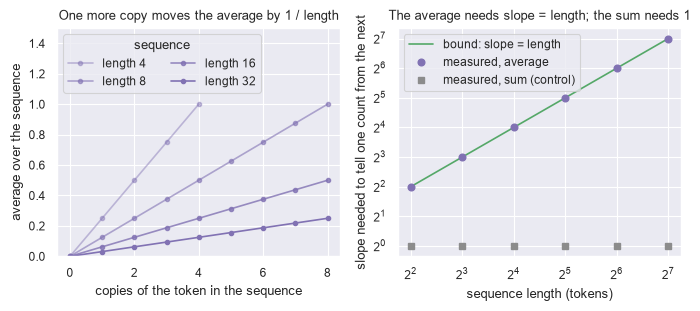

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(7.0, 3.2))
for length, shade in zip([4, 8, 16, 32], [0.45, 0.6, 0.8, 1.0]):
    copies = np.arange(0, min(length, 8) + 1)
    averages, _ = get_average_and_sum(copies, length)
    left.plot(copies, averages, marker="o", markersize=3, color=MODEL, alpha=shade,
              label=f"length {length}")
left.set_xlabel("copies of the token in the sequence")
left.set_ylabel("average over the sequence")
left.set_title("One more copy moves the average by 1 / length")
left.set_ylim(0.0, 1.5)
left.legend(title="sequence", loc="upper left", ncol=2)

lengths_axis = np.array(LENGTHS)
right.plot(lengths_axis, lengths_axis, color=BOUND, label="bound: slope = length")
right.plot(lengths_axis, [required_slope_average[length] for length in LENGTHS], marker="o", linestyle="none",
           color=MODEL, label="measured, average")
right.plot(lengths_axis, [required_slope_sum[length] for length in LENGTHS], marker="s", linestyle="none",
           color=BEFORE, label="measured, sum (control)")
right.set_xscale("log", base=2)
right.set_yscale("log", base=2)
right.set_xlabel("sequence length (tokens)")
right.set_ylabel("slope needed to tell one count from the next")
right.set_title("The average needs slope = length; the sum needs 1")
right.legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "41-average-against-copies")
plt.show()

## Figure 2: the denoiser passes through the half on the way from one count to the next

The chapter's hands A `(5, 0)` and B `(6, 2)`. The input starts at the midpoint of A and B and moves along the line from A
to B by `offset`, from -3 to 3; offset 0 is the input equally far from both. The curves are the finger count the ideal
denoiser returns, at noise levels 0.3, 1 and 3. The grey step is the nearest-example answer (5 for offset below 0, 6
above), which has the jump the chapter says an average avoids. Every smooth curve passes through 5.5 at offset 0.

wrote book/figures/41-denoiser-passes-through-the-half.png


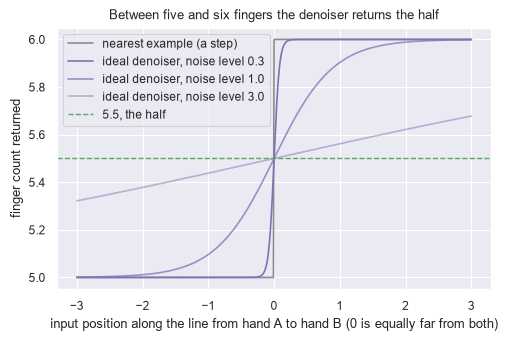

In [7]:
offsets = np.linspace(-3.0, 3.0, 601)
fig, axis = plt.subplots(figsize=(5.6, 3.4))
step = np.where(offsets < 0.0, 5.0, 6.0)
axis.plot(offsets, step, color=BEFORE, label="nearest example (a step)")
for noise_level, shade in zip([0.3, 1.0, 3.0], [1.0, 0.75, 0.5]):
    finger_counts = np.array([denoise_ideally(noise_level, HANDS, midpoint + offset * hand_direction)[0]
                              for offset in offsets])
    axis.plot(offsets, finger_counts, color=MODEL, alpha=shade, label=f"ideal denoiser, noise level {noise_level}")
    at_midpoint = finger_counts[np.argmin(np.abs(offsets))]
    assert abs(at_midpoint - 5.5) < 1e-9
axis.axhline(5.5, color=BOUND, linewidth=1.0, linestyle="--", label="5.5, the half")
axis.set_xlabel("input position along the line from hand A to hand B (0 is equally far from both)")
axis.set_ylabel("finger count returned")
axis.set_title("Between five and six fingers the denoiser returns the half")
axis.legend(loc="upper left")
save_figure(fig, "41-denoiser-passes-through-the-half")
plt.show()

## Summary

The summary line below is built from the measured numbers above.

In [8]:
print(f"half found at fraction {crossings['5 + fraction^2']:.4f} for 5 + fraction^2; hands output "
      f"{denoise_ideally(1.0, HANDS, NOISY_HAND_INPUT)[0]:.4f} at noise 1; slope times distance at least "
      f"{min(smallest[0] for smallest in smallest_ratio.values()):.4f}; average over 128 tokens needs slope "
      f"{required_slope_average[128]:.1f}, the sum {required_slope_sum[128]:.1f}")

half found at fraction 0.7071 for 5 + fraction^2; hands output 5.5000 at noise 1; slope times distance at least 1.1649; average over 128 tokens needs slope 128.0, the sum 1.0
